# PCA trên đặc trưng RFM

Đọc feature khách hàng → log1p → StandardScaler → khảo sát phương sai → giữ ít nhất 90% phương sai → lưu dữ liệu PCA. Đây là nhánh chỉ RFM; CustomerID là khóa, không có target.

## thư viện sử dụng

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## đọc dữ liệu feature

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/feature/customer_features.csv").exists()
            or (p / "project/data/feature/customer_features.csv").exists())
if not (ROOT / "data/feature/customer_features.csv").exists():
    ROOT = ROOT / "project"

feature = pd.read_csv(ROOT / "data/feature/customer_features.csv",
                      dtype={"CustomerID": "string"})
customer_ids = feature["CustomerID"].copy()
X = feature[["Recency", "Frequency", "Monetary"]].copy()
assert customer_ids.notna().all() and customer_ids.is_unique
assert len(X) > 3 and np.isfinite(X).all().all()
assert (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.head()

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
0,3,7,4310.00
1,76,4,1437.24
2,19,1,1457.55
3,311,1,294.40
4,37,7,1385.74


## log và chuẩn hóa dữ liệu

In [3]:
X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
print("Dữ liệu đã chuẩn hóa:", X_scaled.shape)

Dữ liệu đã chuẩn hóa: (4327, 3)


## vẽ tỷ lệ phương sai của toàn bộ thành phần

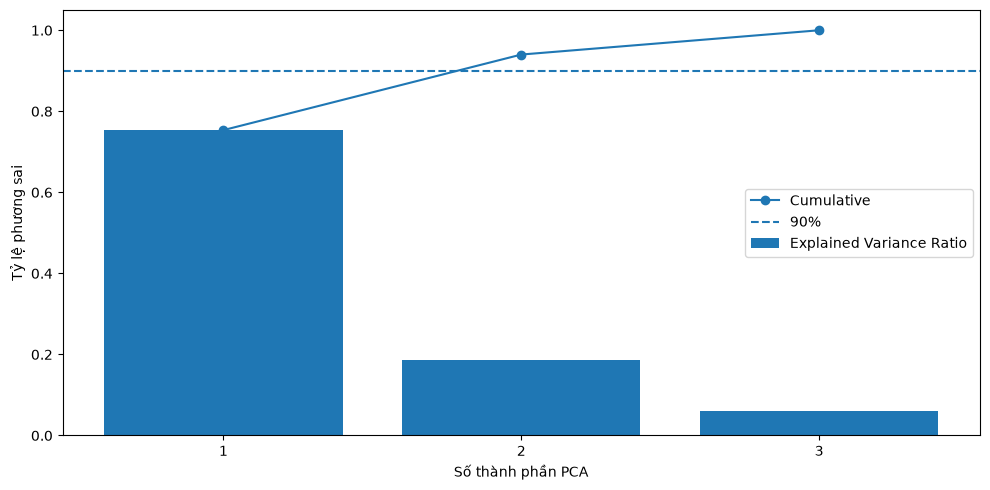

In [4]:
pca_full = PCA(svd_solver="full")
pca_full.fit(X_scaled)
variance = pca_full.explained_variance_ratio_
cumulative = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)
threshold = 0.90

plt.figure(figsize=(10, 5))
plt.plot(components, cumulative, marker="o", label="Cumulative")
plt.axhline(threshold, color="tab:blue", linestyle="--", label=f"{threshold:.0%}")
plt.bar(components, variance, label="Explained Variance Ratio")
plt.xlabel("Số thành phần PCA")
plt.ylabel("Tỷ lệ phương sai")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

n_components = int(np.searchsorted(cumulative, threshold) + 1)

## tạo dữ liệu giảm chiều

In [5]:
pca = PCA(n_components=n_components, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
assert X_pca.shape == (len(feature), n_components)
assert np.isfinite(X_pca).all()
assert pca.explained_variance_ratio_.sum() >= threshold - 1e-12
print("Kích thước sau PCA:", X_pca.shape)
print("Phương sai giữ lại:", pca.explained_variance_ratio_.sum())

Kích thước sau PCA: (4327, 2)
Phương sai giữ lại: 0.9400607165232948


## lưu dữ liệu để phân cụm K-Means

In [6]:
pca_data = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
pca_data.insert(0, "CustomerID", customer_ids.to_numpy())
output_dir = ROOT / "data/feature"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "customer_pca.csv"
pca_data.to_csv(output_path, index=False, encoding="utf-8-sig")

saved = pd.read_csv(output_path, dtype={"CustomerID": "string"})
pd.testing.assert_frame_equal(pca_data, saved, check_dtype=False)
print("Đã lưu:", output_path)
pca_data.head()

Đã lưu: c:\Users\dell\Documents\GitHub\SGU-ML-High-Value-Customer-Prediction\project\data\feature\customer_pca.csv


,CustomerID,PC1,PC2
0,12347,2.496214,-0.668303
1,12348,0.388737,0.677161
2,12349,0.094336,-0.554562
3,12350,-1.742704,0.657891
4,12352,1.073803,0.388215
